In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the metadata
df = pd.read_csv('/content/HAM10000_metadata.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
display(df.head())

Dataset Shape: (10015, 7)

Missing Values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


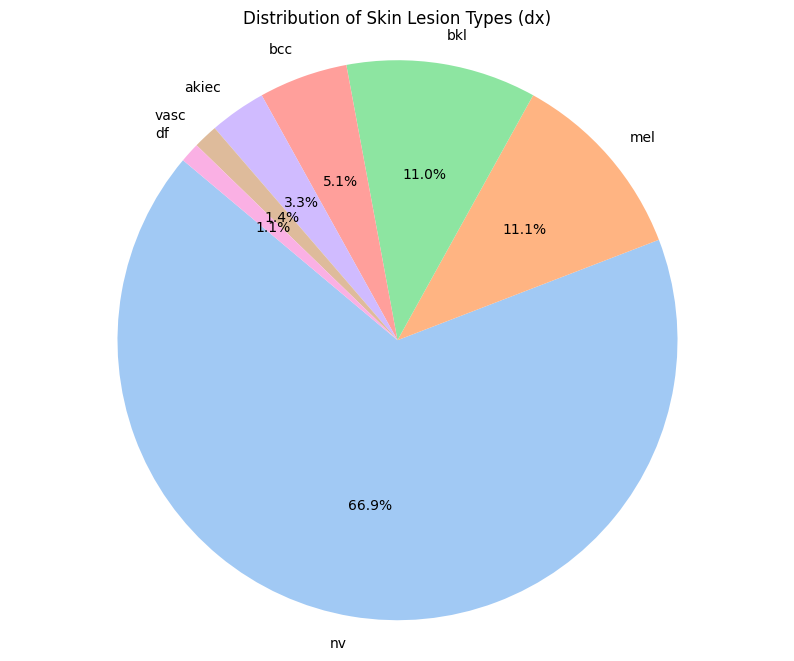

In [2]:
# Calculate class distribution
dx_counts = df['dx'].value_counts()

# Plot pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    dx_counts,
    labels=dx_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')
)
plt.title('Distribution of Skin Lesion Types (dx)')
plt.axis('equal')
plt.show()

### Load Pixel Data and Split Dataset (80/20)
Now, we will load the 28x28 pixel RGB dataset, normalize the pixel values, map the target labels (`dx`), and split the data into training (80%) and testing/validation (20%) sets.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

# 1. Load the 28x28 RGB pixel dataset
# This CSV contains the flattened pixel values (28 * 28 * 3 = 2352 columns) and a label column at the end
pixel_df = pd.read_csv('/content/hmnist_28_28_RGB.csv')

# 2. Extract features (pixels) and target label
# The last column 'label' is the target
X = pixel_df.iloc[:, :-1].values
y = pixel_df.iloc[:, -1].values

# 3. Reshape pixels back to 28x28x3 images and normalize values to [0, 1]
X = X.reshape(-1, 28, 28, 3) / 255.0

# 4. One-hot encode the target label
num_classes = len(np.unique(y))
y = to_categorical(y, num_classes=num_classes)

# 5. Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8012, 28, 28, 3)
Testing set shape: (2003, 28, 28, 3)


### Define and Compile the CNN Model
We will now construct a Convolutional Neural Network architecture designed for image classification tasks.

In [4]:
from tensorflow.keras import layers, models

# Build the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,991 (507.78 KB)

 Trainable params: 129,031 (504.03 KB)

 Non-trainable params: 960 (3.75 KB)

### Train the CNN Model
We will now train the CNN on the 80% training dataset and validate it using the remaining 20% dataset over 10 epochs.

In [ ]:
# Train the compiled model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.7574 - loss: 0.6603 - val_accuracy: 0.7164 - val_loss: 0.8372
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step - accuracy: 0.7654 - loss: 0.6444 - val_accuracy: 0.7189 - val_loss: 0.8442
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.7640 - loss: 0.6449 - val_accuracy: 0.7139 - val_loss: 0.9244
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.7646 - loss: 0.6415 - val_accuracy: 0.7184 - val_loss: 0.8142
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.7639 - loss: 0.6360 - val_accuracy: 0.7489 - val_loss: 0.6866
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 14s 54ms/step - accuracy: 0.7677 - loss: 0.6332 - val_accuracy: 0.7189 - val_loss: 0.9413
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.7666 - loss: 0.6229 - val_accuracy: 0.7354 - val_loss: 0.6991
Epoch 8/10
 92/251 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.7514 - loss: 0.6588

### Train the CNN Model
We will now train the CNN on the 80% training dataset and validate it using the remaining 20% dataset over 10 epochs.

In [6]:
# Train the compiled model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 14s 54ms/step - accuracy: 0.7335 - loss: 0.7247 - val_accuracy: 0.6680 - val_loss: 0.9190
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.7406 - loss: 0.7132 - val_accuracy: 0.6715 - val_loss: 1.9657
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.7408 - loss: 0.7056 - val_accuracy: 0.7034 - val_loss: 0.7827
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.7419 - loss: 0.6942 - val_accuracy: 0.6920 - val_loss: 1.0663
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.7475 - loss: 0.6863 - val_accuracy: 0.6890 - val_loss: 0.7633
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.7378 - loss: 0.7029 - val_accuracy: 0.6960 - val_loss: 1.1271
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - accuracy: 0.7491 - loss: 0.6846 - val_accuracy: 0.7239 - val_loss: 0.7819
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - accuracy: 0.7488 - loss: 0.6733 - 

### Plot Training Loss and Accuracy
We will plot the accuracy and loss curves for both the training and validation splits to evaluate performance and look for overfitting.

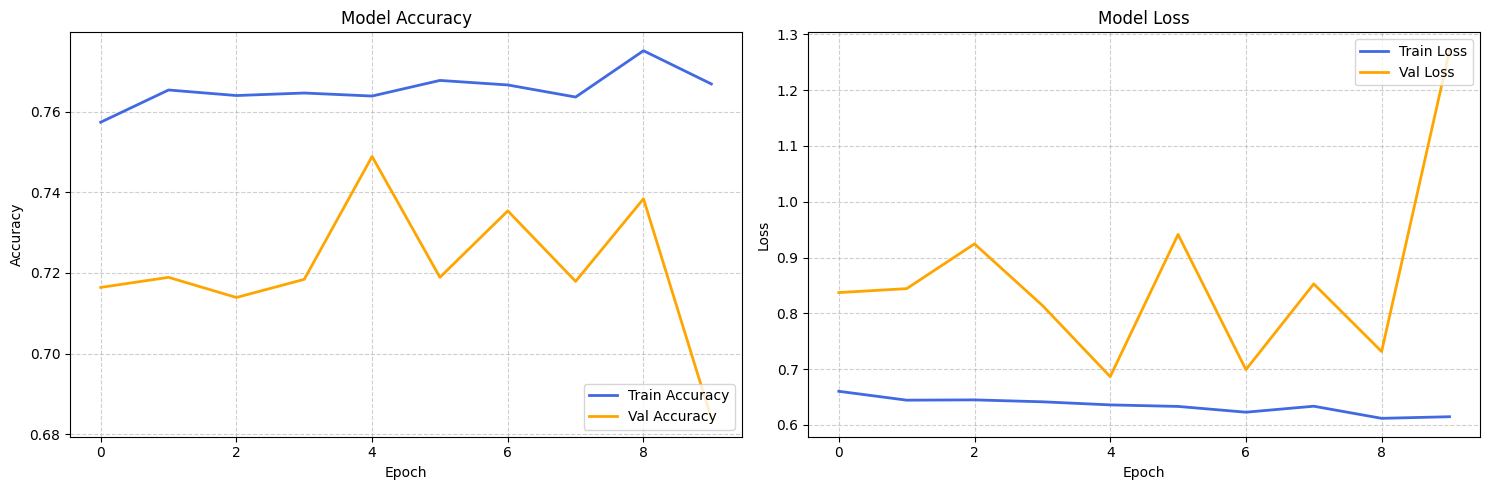

In [10]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot training & validation accuracy
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='royalblue', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot training & validation loss
ax2.plot(history.history['loss'], label='Train Loss', color='royalblue', linewidth=2)
ax2.plot(history.history['val_loss'], label='Val Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Evaluate Model Performance with a Confusion Matrix
Now, we will generate predictions on our test set and plot a confusion matrix to identify which skin lesion classes are being predicted correctly or incorrectly.

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


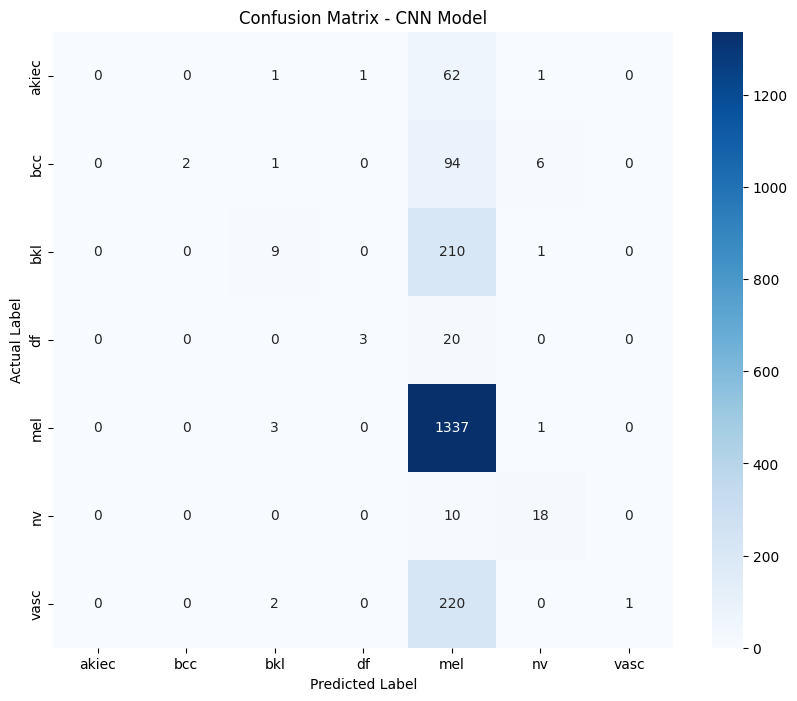


Classification Report:
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        65
         bcc       1.00      0.02      0.04       103
         bkl       0.56      0.04      0.08       220
          df       0.75      0.13      0.22        23
         mel       0.68      1.00      0.81      1341
          nv       0.67      0.64      0.65        28
        vasc       1.00      0.00      0.01       223

    accuracy                           0.68      2003
   macro avg       0.67      0.26      0.26      2003
weighted avg       0.70      0.68      0.57      2003



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate predictions for the test set
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

# 2. Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Class names mapped sequentially from the label encoder / unique classes
# Based on the metadata unique classes sorting
class_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

# 3. Plot the confusion matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - CNN Model')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# 4. Print classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

### Sample Predictions and Classification Report
Let's run predictions on a few individual samples from the test set to see the model's performance in action, and display the classification report.

In [12]:
import numpy as np
from sklearn.metrics import classification_report

# 1. Print classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# 2. Show sample predictions
print("\n--- Sample Predictions vs Actual Labels ---")
for i in range(10):
    true_idx = y_true[i]
    pred_idx = y_pred[i]
    confidence = y_pred_probs[i][pred_idx] * 100

    print(f"Sample {i+1}: True Label: {class_names[true_idx]:<6} | Predicted: {class_names[pred_idx]:<6} ({confidence:.2f}% confidence)")

Classification Report:
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        65
         bcc       1.00      0.02      0.04       103
         bkl       0.56      0.04      0.08       220
          df       0.75      0.13      0.22        23
         mel       0.68      1.00      0.81      1341
          nv       0.67      0.64      0.65        28
        vasc       1.00      0.00      0.01       223

    accuracy                           0.68      2003
   macro avg       0.67      0.26      0.26      2003
weighted avg       0.70      0.68      0.57      2003


--- Sample Predictions vs Actual Labels ---
Sample 1: True Label: vasc   | Predicted: mel    (75.72% confidence)
Sample 2: True Label: bkl    | Predicted: mel    (86.15% confidence)
Sample 3: True Label: mel    | Predicted: mel    (99.30% confidence)
Sample 4: True Label: mel    | Predicted: mel    (99.51% confidence)
Sample 5: True Label: mel    | Predicted: mel    (99.75% co

### Preparing for Streamlit Deployment & GitHub

To run your skin lesion classifier application on **Streamlit Cloud**, you will need a couple of files in your GitHub repository:

1. `app.py`: Your Streamlit application code.
2. `requirements.txt`: Specifies the libraries Streamlit must install.
3. `best_model.keras` (or `.h5`): Your trained CNN model weights (save your model first!).

Let's generate the `requirements.txt` programmatically right here.

In [14]:
# Save the current trained model to disk so you can download it and upload to your GitHub repo
model.save('skin_lesion_model.keras')
print("Model saved as 'skin_lesion_model.keras'")

# Create the requirements.txt file
requirements = """\
streamlit
tensorflow
numpy
pandas
pillow
scikit-learn
matplotlib
seaborn
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements)

print("requirements.txt has been generated successfully!")

Model saved as 'skin_lesion_model.keras'
requirements.txt has been generated successfully!


### Saving and Downloading the Model Files
Below we save the model using both the newer Keras format (`.keras`) and the legacy HDF5 format (`.h5`), and provide a script to download the model directly to your computer.

In [16]:
from google.colab import files

# Save in different standard formats
model.save('skin_lesion_model.keras')
model.save('skin_lesion_model.h5')

print("Model saved successfully in both .keras and .h5 formats!")

# Trigger automatic download from browser
try:
    files.download('skin_lesion_model.keras')
except Exception as e:
    print("Could not trigger automatic download. You can download 'skin_lesion_model.keras' manually from the files tab on the left.")

Model saved successfully in both .keras and .h5 formats!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Creating the Streamlit App (`app.py`)
We can write the Streamlit interface file programmatically. This script loads our saved model, accepts an uploaded skin image, reshapes and normalizes it to match our network's input (28x28 RGB), and outputs the prediction.

In [15]:
app_code = """\
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.title("Skin Lesion Classification App")
st.write("Upload an image of a skin lesion to get a prediction from our trained CNN model.")

# Load the saved model
@st.cache_resource
def load_my_model():
    return tf.keras.models.load_model('skin_lesion_model.keras')

try:
    model = load_my_model()
    st.success("Model loaded successfully!")
except Exception as e:
    st.error(f"Error loading model: {e}")

# Class names ordered logically
class_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
class_map = {
    'akiec': 'Actinic keratoses and intraepithelial carcinoma',
    'bcc': 'Basal cell carcinoma',
    'bkl': 'Benign keratosis-like lesions',
    'df': 'Dermatofibroma',
    'mel': 'Melanoma',
    'nv': 'Melanocytic nevi',
    'vasc': 'Vascular lesions'
}

uploaded_file = st.file_uploader("Choose a skin lesion image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    image = Image.open(uploaded_file)
    st.image(image, caption='Uploaded Image', use_container_width=True)

    st.write("Classifying...")

    # Preprocess image to match training: 28x28 RGB normalized to [0,1]
    resized_image = image.resize((28, 28)).convert('RGB')
    img_array = np.array(resized_image) / 255.0
    img_array = np.expand_dims(img_array, axis=0) # Add batch dimension (1, 28, 28, 3)

    # Make prediction
    predictions = model.predict(img_array)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class_name = class_names[predicted_class_idx]
    confidence = predictions[0][predicted_class_idx] * 100

    st.subheader(f"Prediction: {class_map[predicted_class_name]} ({predicted_class_name})")
    st.write(f"Confidence: {confidence:.2f}%")

    # Display all probabilities
    st.write("### Class Probabilities:")
    for name, prob in zip(class_names, predictions[0]):
        st.write(f"- **{class_map[name]} ({name})**: {prob*100:.2f}%")
"""

with open('app.py', 'w') as f:
    f.write(app_code)

print("app.py has been generated successfully!")

app.py has been generated successfully!
